# Lab 6 — Reinforcement learning

**Goal.** Train tabular Q-learning, evaluate the greedy policy, visualize values and actions, and save the Q-table.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

## Part A — Tabular Q-learning in a 4×4 GridWorld

In [2]:
rng = np.random.default_rng(42)

ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]        # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

In [3]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))       # explore: random move
    return int(np.argmax(Q[state]))                  # exploit: best known move

training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

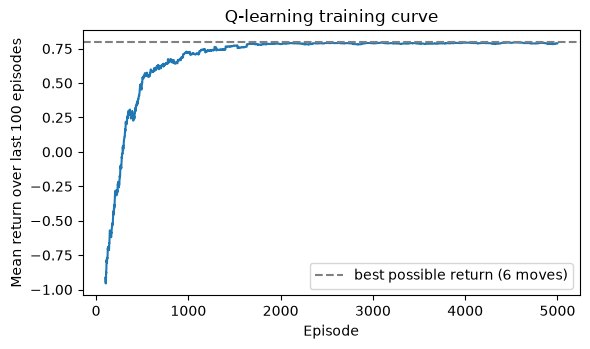

In [4]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


**Interpretation.** The training curve starts low because ε = 1 makes every move random, so the agent often walks into the trap or wanders. As ε decays, the mean return rises towards the best possible value of 0.80. It stays slightly below 0.80 because ε never drops below 0.05, so a few random moves still happen during training.

With exploration turned off, the greedy policy reaches the goal in all 200 evaluation episodes (success rate 1.0) with a mean return of 0.80. A return of 0.80 equals 5 × (−0.04) + 1, so the agent takes the shortest 6-move route every time. Its first action from the start is down.

## Part B — The Q-table is the model: save it and read the policy

In [14]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)

Q_loaded = np.load(q_path)
policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


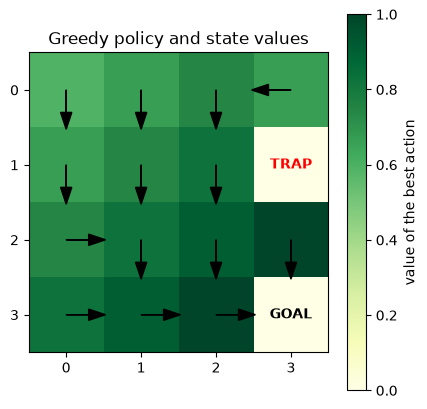

In [15]:
def plot_policy(Q_table, title):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == TRAP:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_policy(Q_loaded, "Greedy policy and state values")

In [16]:
values = Q_loaded.max(axis=2).round(3)
print("Best Q-value in each cell (GOAL and TRAP cells are never updated, so they stay 0):")
print(values)

Best Q-value in each cell (GOAL and TRAP cells are never updated, so they stay 0):
[[0.593 0.666 0.743 0.666]
 [0.666 0.743 0.824 0.   ]
 [0.743 0.824 0.91  1.   ]
 [0.824 0.91  1.    0.   ]]


**Interpretation.** The Q-table is saved to `models/gridworld_q_table.npy` and reloaded, and the policy is read from the reloaded table without any retraining.

From the start, the greedy route is down → down → right → down → right → right, which reaches the goal in 6 moves. The route goes down the left side first and stays away from the trap at (1, 3). The cell at (0, 3), next to the trap, points left, away from the trap.

The values rise as cells get closer to the goal, from 0.593 at the start to 1.0 next to the goal. Each step back from the goal multiplies the value by γ = 0.95 and adds the −0.04 step cost. For example, the start value is −0.04 × (1 + 0.95 + 0.95² + 0.95³ + 0.95⁴) + 0.95⁵ = 0.593, which matches the table. Several actions often tie for the best value, because many 6-move routes exist, and `argmax` picks the first one.

## Try it yourself — change the settings, predict, retrain and check

The training loop is wrapped in a function so that the step cost, trap position, discount and exploration schedule can change. `plot_policy` and the original `Q` are not changed. Because `plot_policy` reads the global `TRAP`, the function sets it for each experiment and then restores it.

In [17]:
def train_and_evaluate(step_cost=-0.04, trap=(1, 3), gamma_=0.95, decay=0.9985,
                       min_eps=0.05, episodes=5000, seed=42):
    """Train Q-learning with the given settings. Returns the Q-table and greedy evaluation results."""
    rng_ = np.random.default_rng(seed)
    Q_ = np.zeros((ROWS, COLS, len(ACTIONS)))
    eps = 1.0

    def step_(state, action):
        r, c = state
        dr, dc = ACTIONS[action]
        nxt = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
        if nxt == GOAL:
            return nxt, 1.0, True
        if nxt == trap:
            return nxt, -1.0, True
        return nxt, step_cost, False

    for _ in range(episodes):
        state = START
        for _ in range(100):
            if rng_.random() < eps:
                a = int(rng_.integers(len(ACTIONS)))
            else:
                a = int(np.argmax(Q_[state]))
            nxt, reward, done = step_(state, a)
            target = reward if done else reward + gamma_ * np.max(Q_[nxt])
            Q_[state][a] += alpha * (target - Q_[state][a])
            state = nxt
            if done:
                break
        eps = max(min_eps, eps * decay)

    # Greedy evaluation: exploration off. The environment is deterministic, so one run is enough.
    state, total, moves, outcome = START, 0.0, 0, "timeout (100 moves)"
    for _ in range(100):
        state, reward, done = step_(state, int(np.argmax(Q_[state])))
        total += reward
        moves += 1
        if done:
            outcome = "GOAL" if state == GOAL else "TRAP"
            break
    return Q_, outcome, moves, round(total, 3)

def run_experiment(title, **settings):
    global TRAP
    old_trap = TRAP
    TRAP = settings.get("trap", (1, 3))
    Q_exp, outcome, moves, total = train_and_evaluate(**settings)
    print(f"{title}: greedy run ends at {outcome} after {moves} moves, return = {total}")
    plot_policy(Q_exp, title)
    TRAP = old_trap
    return Q_exp

### Experiment 1 — A very high step cost (−2 per move)

**Prediction.** A move now costs −2, which is twice as bad as the trap's −1. The route to the goal takes 6 moves, for a return of 5 × (−2) + 1 = −9. The shortest route into the trap takes 4 moves, for a return of 3 × (−2) − 1 = −7. The agent will therefore prefer to end the episode in the trap as quickly as possible.

Step cost -2: greedy run ends at TRAP after 4 moves, return = -7.0


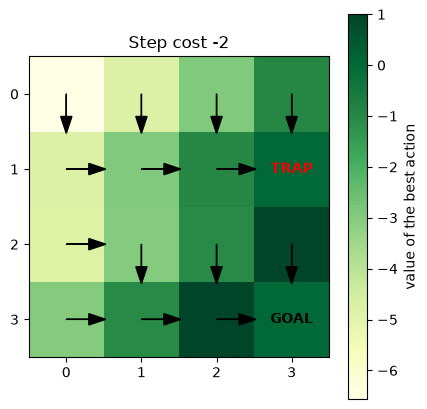

In [18]:
Q_cost = run_experiment("Step cost -2", step_cost=-2.0)

**Result.** The prediction was correct. The greedy agent walks straight into the trap in 4 moves, with a return of −7. This shows that the agent only maximises total reward. If the reward design makes staying alive too costly, the "best" policy can be one that the designer did not want.

### Experiment 2 — Move the trap to (2, 2)

**Prediction.** Moving the trap to (2, 2) blocks the middle of the grid. Many shortest routes still exist around the edges, such as down the left side and then along the bottom row. The agent will still reach the goal in 6 moves, with a return of 0.80, and the arrows near (2, 2) will point around it.

Trap moved to (2, 2): greedy run ends at GOAL after 6 moves, return = 0.8


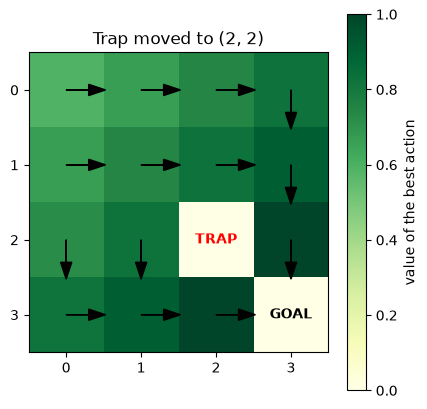

In [19]:
Q_trap = run_experiment("Trap moved to (2, 2)", trap=(2, 2))

**Result.** The prediction was correct. The agent reaches the goal in 6 moves with a return of 0.80, and the policy plot shows the arrows routing around the new trap position.

### Experiment 3 — No step cost and no discounting (step cost 0, γ = 1)

**Prediction.** With no step cost and γ = 1, a long safe route earns the same total reward (+1) as the shortest route. The agent will no longer have a reason to prefer short routes, so the values will become flat and the route may be longer than 6 moves.

Step cost 0, gamma 1: greedy run ends at GOAL after 6 moves, return = 1.0


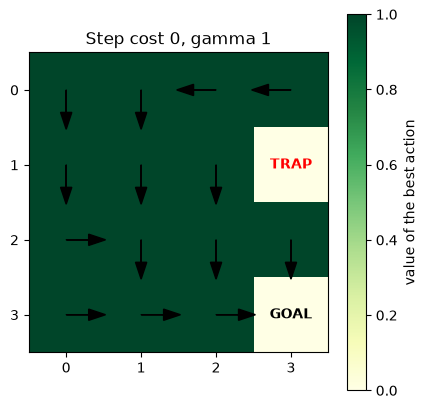

In [20]:
Q_flat = run_experiment("Step cost 0, gamma 1", step_cost=0.0, gamma_=1.0)

**Result.** The prediction was partly correct. The value map becomes completely flat, with every safe cell worth about 1.0, so the agent cannot tell short and long routes apart. In this run, and in ten repeated runs with different seeds, the greedy route still happened to take 6 moves. This happened because of small leftover differences in the Q-values, not because the agent preferred short routes. The return is now 1.0 for any route that reaches the goal, so a shorter route earns nothing extra. A step cost or a discount below 1 is what makes the agent prefer the shortest route.

### Experiment 4 — Exploration that decays too fast

**Prediction.** With a decay of 0.9 and no minimum, ε falls close to 0 within about 50 episodes. The agent will stop exploring very early and will likely get stuck on whatever route it found first, which may be longer than 6 moves. The original schedule is run with the same five seeds for comparison.

In [21]:
for seed in range(5):
    _, outcome, moves, total = train_and_evaluate(decay=0.9, min_eps=0.0, episodes=5000, seed=seed)
    print(f"fast decay, seed {seed}: {outcome} after {moves} moves, return = {total}")
print()
for seed in range(5):
    _, outcome, moves, total = train_and_evaluate(seed=seed)
    print(f"original schedule, seed {seed}: {outcome} after {moves} moves, return = {total}")

fast decay, seed 0: GOAL after 6 moves, return = 0.8
fast decay, seed 1: GOAL after 6 moves, return = 0.8
fast decay, seed 2: GOAL after 6 moves, return = 0.8
fast decay, seed 3: GOAL after 6 moves, return = 0.8
fast decay, seed 4: GOAL after 6 moves, return = 0.8

original schedule, seed 0: GOAL after 6 moves, return = 0.8
original schedule, seed 1: GOAL after 6 moves, return = 0.8
original schedule, seed 2: GOAL after 6 moves, return = 0.8
original schedule, seed 3: GOAL after 6 moves, return = 0.8
original schedule, seed 4: GOAL after 6 moves, return = 0.8


**Result.** The prediction was wrong. The fast schedule still finds the 6-move route with every seed. The reason is the starting Q-values. They all start at 0, and every normal move costs −0.04, so an action that has been tried drops below 0 while untried actions stay at 0. The greedy agent then picks the untried actions, so it keeps exploring even with ε = 0. This is called optimistic initialisation. On a small 16-cell grid, this is enough to discover the best route. In a larger or noisier environment, decaying exploration this quickly would be much riskier.

## Check your understanding

**1. What are the state, action, reward and transition in a reinforcement learning formulation?**

The state describes the agent's current situation, which here is its (row, column) cell. The action is the choice the agent makes in that state, which here is up, down, left or right. The reward is the number the environment returns after the action, which here is −0.04 for a normal move, +1 for the goal and −1 for the trap. The transition is the rule that gives the next state from the current state and action, which here is `step()`, where moving into a wall leaves the agent in the same cell.

**2. What two pieces of information appear in the tabular Q-learning backup value?**

The backup target is r + γ · max Q(s′, a′). It combines the immediate reward r from the action that was taken, and the discounted estimate of the best value available from the next state s′. Q(s, a) then moves towards this target by a step of size α.

**3. Why should the exploratory training policy be evaluated separately from the final greedy policy?**

During training, the agent sometimes takes random actions because of ε-greedy exploration. These random moves lower the training returns, so the training curve stays below the true performance of the learned policy. The deployed agent will always pick its best action, so it has to be tested with exploration turned off. Evaluating separately shows what the final policy really achieves (here, 1.0 success and a 0.80 return) and does not mix in the cost of exploration.